Project 02 — Supermarket Sales Analysis
Business objective: Analyze supermarket transaction data to understand sales performance, customer purchasing behavior, product-line profitability, branch performance, and payment preferences.

1. What we will investigate
•	Which product lines generate the most revenue?
•	Which branches perform best, and why?
•	Which customer types and membership groups spend more?
•	Do sales vary by day, time, or month?
•	Which payment methods are most commonly used?
•	How do gross income and customer ratings vary across product lines?
•	What actionable recommendations could improve supermarket performance?
One important distinction: the dataset includes a gross income field, which we can analyze as a profitability-related measure. We should not automatically treat it as the supermarket's total net profit.



In [2]:
%pip install pandas numpy matplotlib seaborn jupyter

   ---------------------------------------- 0.0/2.2 MB ? eta -:--:--
   ---- ----------------------------------- 0.3/2.2 MB ? eta -:--:--
   ----------------------- ---------------- 1.3/2.2 MB 3.5 MB/s eta 0:00:01
   ------------------------------------- -- 2.1/2.2 MB 3.6 MB/s eta 0:00:01
   ---------------------------------------- 2.2/2.2 MB 3.1 MB/s  0:00:00
   ---------------------------------------- 0.0/17.2 MB ? eta -:--:--
   - -------------------------------------- 0.8/17.2 MB 3.4 MB/s eta 0:00:05
   ---- ----------------------------------- 1.8/17.2 MB 4.0 MB/s eta 0:00:04
   ----- ---------------------------------- 2.4/17.2 MB 3.8 MB/s eta 0:00:04
   ------ --------------------------------- 2.6/17.2 MB 3.7 MB/s eta 0:00:04
   ------ --------------------------------- 2.6/17.2 MB 3.7 MB/s eta 0:00:04
   ------- -------------------------------- 3.1/17.2 MB 2.4 MB/s eta 0:00:06
   ------- -------------------------------- 3.1/17.2 MB 2.4 MB/s eta 0:00:06
   --------- ---------------


[notice] A new release of pip is available: 25.3 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [5]:
# Load the dataset
df = pd.read_csv("C:/Users/prath/OneDrive/Desktop/Data Science Project/SuperMarket Sales Analysis/supermarket_sales.csv")

# Display the first five records
df.head()

,Invoice ID,Branch,City,Customer type,Gender,Product line,Unit price,Quantity,Tax 5%,Total,Date,Time,Payment,cogs,gross margin percentage,gross income,Rating
0,750-67-8428,A,Yangon,Member,Female,Health and beauty,74.69,7,26.1415,548.9715,1/5/2019,13:08,Ewallet,522.83,4.761905,26.1415,9.1
1,226-31-3081,C,Naypyitaw,Normal,Female,Electronic accessories,15.28,5,3.8200,80.2200,3/8/2019,10:29,Cash,76.40,4.761905,3.8200,9.6
2,631-41-3108,A,Yangon,Normal,Male,Home and lifestyle,46.33,7,16.2155,340.5255,3/3/2019,13:23,Credit card,324.31,4.761905,16.2155,7.4
3,123-19-1176,A,Yangon,Member,Male,Health and beauty,58.22,8,23.2880,489.0480,1/27/2019,20:33,Ewallet,465.76,4.761905,23.2880,8.4
4,373-73-7910,A,Yangon,Normal,Male,Sports and travel,86.31,7,30.2085,634.3785,2/8/2019,10:37,Ewallet,604.17,4.761905,30.2085,5.3


In [6]:
# Display the number of rows and columns
print("Dataset dimensions:", df.shape)

# Display all column names
print("\nColumn names:")
print(df.columns.tolist())

# Display column data types and non-null counts
print("\nDataset information:")
df.info()

Dataset dimensions: (1000, 17)

Column names:
['Invoice ID', 'Branch', 'City', 'Customer type', 'Gender', 'Product line', 'Unit price', 'Quantity', 'Tax 5%', 'Total', 'Date', 'Time', 'Payment', 'cogs', 'gross margin percentage', 'gross income', 'Rating']

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 17 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Invoice ID               1000 non-null   object 
 1   Branch                   1000 non-null   object 
 2   City                     1000 non-null   object 
 3   Customer type            1000 non-null   object 
 4   Gender                   1000 non-null   object 
 5   Product line             1000 non-null   object 
 6   Unit price               1000 non-null   float64
 7   Quantity                 1000 non-null   int64  
 8   Tax 5%                   1000 non-null   float64
 9   Total             

In [7]:
# Summary statistics for numerical columns
df.describe()

,Unit price,Quantity,Tax 5%,Total,cogs,gross margin percentage,gross income,Rating
count,1000.000000,1000.000000,1000.000000,1000.000000,1000.00000,1000.000000,1000.000000,1000.00000
mean,55.672130,5.510000,15.379369,322.966749,307.58738,4.761905,15.379369,6.97270
std,26.494628,2.923431,11.708825,245.885335,234.17651,0.000000,11.708825,1.71858
min,10.080000,1.000000,0.508500,10.678500,10.17000,4.761905,0.508500,4.00000
25%,32.875000,3.000000,5.924875,124.422375,118.49750,4.761905,5.924875,5.50000
50%,55.230000,5.000000,12.088000,253.848000,241.76000,4.761905,12.088000,7.00000
75%,77.935000,8.000000,22.445250,471.350250,448.90500,4.761905,22.445250,8.50000
max,99.960000,10.000000,49.650000,1042.650000,993.00000,4.761905,49.650000,10.00000


In [8]:
# Count missing values in each column
missing_values = df.isnull().sum()

print("Missing values by column:")
print(missing_values)

print("\nTotal missing values:", missing_values.sum())

Missing values by column:
Invoice ID                 0
Branch                     0
City                       0
Customer type              0
Gender                     0
Product line               0
Unit price                 0
Quantity                   0
Tax 5%                     0
Total                      0
Date                       0
Time                       0
Payment                    0
cogs                       0
gross margin percentage    0
gross income               0
Rating                     0
dtype: int64

Total missing values: 0


In [9]:
# Count completely duplicated rows
print("Duplicate rows:", df.duplicated().sum())

# Check duplicate invoice IDs
print("Duplicate invoice IDs:", df["Invoice ID"].duplicated().sum())

Duplicate rows: 0
Duplicate invoice IDs: 0


In [10]:
# Inspect unique values in categorical columns
categorical_columns = [
    "Branch",
    "City",
    "Customer type",
    "Gender",
    "Product line",
    "Payment"
]

for column in categorical_columns:
    print(f"\n{column}:")
    print(sorted(df[column].unique()))


Branch:
['A', 'B', 'C']

City:
['Mandalay', 'Naypyitaw', 'Yangon']

Customer type:
['Member', 'Normal']

Gender:
['Female', 'Male']

Product line:
['Electronic accessories', 'Fashion accessories', 'Food and beverages', 'Health and beauty', 'Home and lifestyle', 'Sports and travel']

Payment:
['Cash', 'Credit card', 'Ewallet']


In [11]:
# Create a working copy
df_clean = df.copy()

# Convert Date to datetime
df_clean["Date"] = pd.to_datetime(
    df_clean["Date"],
    format="%m/%d/%Y",
    errors="coerce"
)

# Convert Time to datetime
df_clean["Time"] = pd.to_datetime(
    df_clean["Time"],
    format="%H:%M",
    errors="coerce"
)

# Verify the converted columns
print(df_clean[["Date", "Time"]].dtypes)

# Check whether conversion introduced missing values
print("\nInvalid dates:", df_clean["Date"].isna().sum())
print("Invalid times:", df_clean["Time"].isna().sum())

Date    datetime64[ns]
Time    datetime64[ns]
dtype: object

Invalid dates: 0
Invalid times: 0


In [12]:
# Create time-based features
df_clean["Month"] = df_clean["Date"].dt.month
df_clean["Month_Name"] = df_clean["Date"].dt.month_name()
df_clean["Day"] = df_clean["Date"].dt.day
df_clean["Day_Name"] = df_clean["Date"].dt.day_name()
df_clean["Hour"] = df_clean["Time"].dt.hour

# Verify the new features
df_clean[
    ["Date", "Month_Name", "Day_Name", "Hour", "Total"]
].head()

,Date,Month_Name,Day_Name,Hour,Total
0,2019-01-05,January,Saturday,13,548.9715
1,2019-03-08,March,Friday,10,80.2200
2,2019-03-03,March,Sunday,13,340.5255
3,2019-01-27,January,Sunday,20,489.0480
4,2019-02-08,February,Friday,10,634.3785


In [13]:
# Calculate key business metrics
total_revenue = df_clean["Total"].sum()
total_transactions = df_clean["Invoice ID"].nunique()
total_units_sold = df_clean["Quantity"].sum()
average_transaction_value = df_clean["Total"].mean()
total_gross_income = df_clean["gross income"].sum()
average_rating = df_clean["Rating"].mean()

# Display the KPIs
print("SUPERMARKET SALES KPI REPORT")
print("-" * 35)

print(f"Total Revenue: MMK {total_revenue:,.2f}")
print(f"Total Transactions: {total_transactions:,}")
print(f"Total Units Sold: {total_units_sold:,}")
print(f"Average Transaction Value: MMK {average_transaction_value:,.2f}")
print(f"Total Gross Income: MMK {total_gross_income:,.2f}")
print(f"Average Customer Rating: {average_rating:.2f}/10")

SUPERMARKET SALES KPI REPORT
-----------------------------------
Total Revenue: MMK 322,966.75
Total Transactions: 1,000
Total Units Sold: 5,510
Average Transaction Value: MMK 322.97
Total Gross Income: MMK 15,379.37
Average Customer Rating: 6.97/10


In [14]:
product_analysis = (
    df_clean.groupby("Product line")
    .agg(
        Total_Revenue=("Total", "sum"),
        Total_Gross_Income=("gross income", "sum"),
        Units_Sold=("Quantity", "sum"),
        Transactions=("Invoice ID", "nunique"),
        Average_Rating=("Rating", "mean")
    )
    .sort_values("Total_Revenue", ascending=False)
)

product_analysis.round(2)

,Total_Revenue,Total_Gross_Income,Units_Sold,Transactions,Average_Rating
Product line,,,,,
Food and beverages,56144.84,2673.56,952,174,7.11
Sports and travel,55122.83,2624.90,920,166,6.92
Electronic accessories,54337.53,2587.50,971,170,6.92
Fashion accessories,54305.90,2586.00,902,178,7.03
Home and lifestyle,53861.91,2564.85,911,160,6.84
Health and beauty,49193.74,2342.56,854,152,7.00


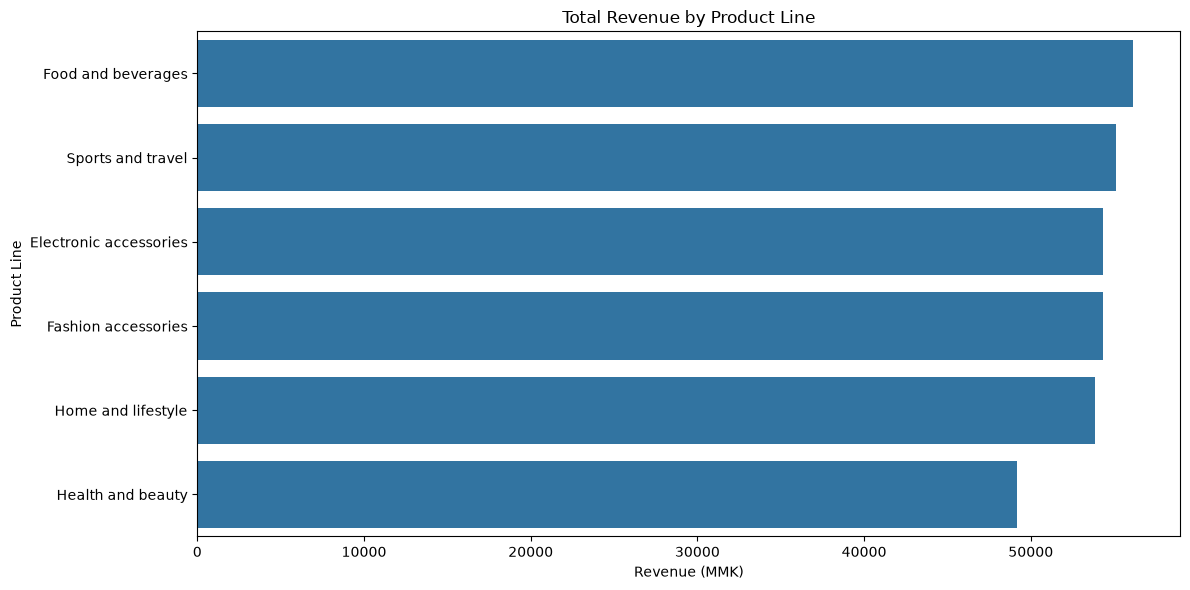

In [15]:
plt.figure(figsize=(12, 6))

sns.barplot(
    data=product_analysis.reset_index(),
    x="Total_Revenue",
    y="Product line"
)

plt.title("Total Revenue by Product Line")
plt.xlabel("Revenue (MMK)")
plt.ylabel("Product Line")
plt.tight_layout()
plt.show()

In [16]:
branch_analysis = (
    df_clean.groupby(["Branch", "City"])
    .agg(
        Total_Revenue=("Total", "sum"),
        Total_Gross_Income=("gross income", "sum"),
        Transactions=("Invoice ID", "nunique"),
        Units_Sold=("Quantity", "sum"),
        Average_Rating=("Rating", "mean")
    )
    .sort_values("Total_Revenue", ascending=False)
)

branch_analysis.round(2)

,,Total_Revenue,Total_Gross_Income,Transactions,Units_Sold,Average_Rating
Branch,City,,,,,
C,Naypyitaw,110568.71,5265.18,328,1831,7.07
A,Yangon,106200.37,5057.16,340,1859,7.03
B,Mandalay,106197.67,5057.03,332,1820,6.82


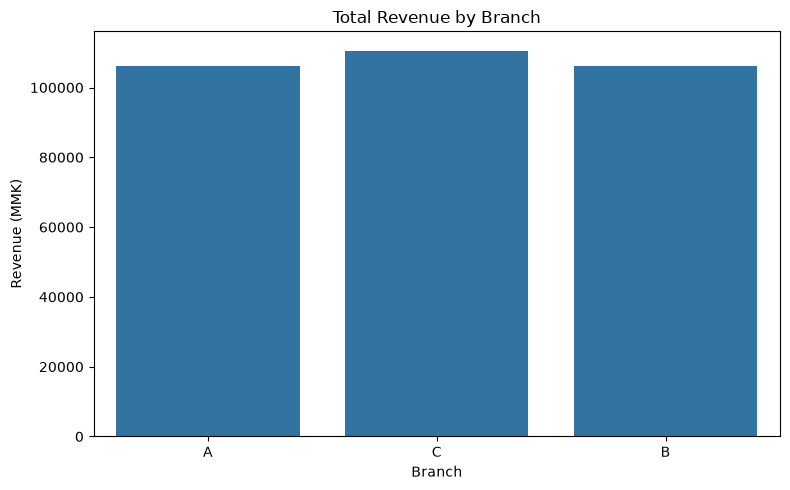

In [17]:
plt.figure(figsize=(8, 5))

sns.barplot(
    data=df_clean,
    x="Branch",
    y="Total",
    estimator="sum",
    errorbar=None
)

plt.title("Total Revenue by Branch")
plt.xlabel("Branch")
plt.ylabel("Revenue (MMK)")
plt.tight_layout()
plt.show()

In [18]:
customer_analysis = (
    df_clean.groupby("Customer type")
    .agg(
        Total_Revenue=("Total", "sum"),
        Transactions=("Invoice ID", "nunique"),
        Average_Transaction_Value=("Total", "mean"),
        Units_Sold=("Quantity", "sum"),
        Average_Rating=("Rating", "mean")
    )
)

customer_analysis.round(2)

,Total_Revenue,Transactions,Average_Transaction_Value,Units_Sold,Average_Rating
Customer type,,,,,
Member,164223.44,501,327.79,2785,6.94
Normal,158743.30,499,318.12,2725,7.01


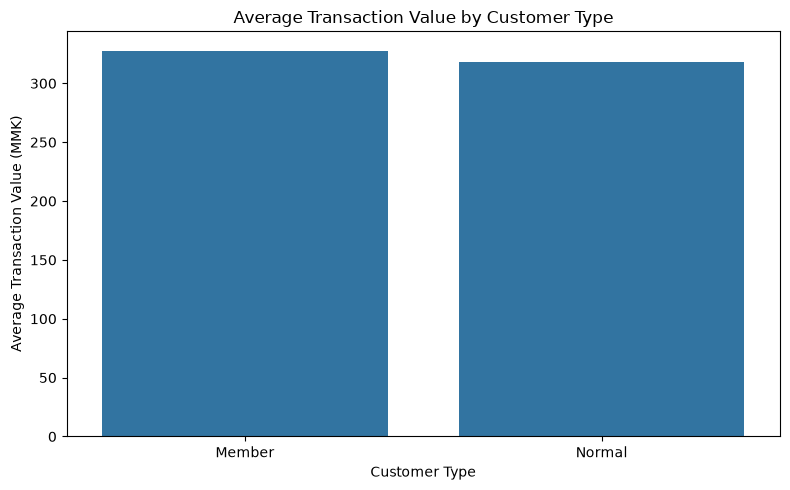

In [19]:
plt.figure(figsize=(8, 5))

sns.barplot(
    data=df_clean,
    x="Customer type",
    y="Total",
    estimator="mean",
    errorbar=None
)

plt.title("Average Transaction Value by Customer Type")
plt.xlabel("Customer Type")
plt.ylabel("Average Transaction Value (MMK)")
plt.tight_layout()
plt.show()

In [20]:
payment_analysis = (
    df_clean.groupby("Payment")
    .agg(
        Transactions=("Invoice ID", "nunique"),
        Total_Revenue=("Total", "sum"),
        Average_Transaction_Value=("Total", "mean")
    )
    .sort_values("Transactions", ascending=False)
)

payment_analysis.round(2)

,Transactions,Total_Revenue,Average_Transaction_Value
Payment,,,
Ewallet,345,109993.11,318.82
Cash,344,112206.57,326.18
Credit card,311,100767.07,324.01


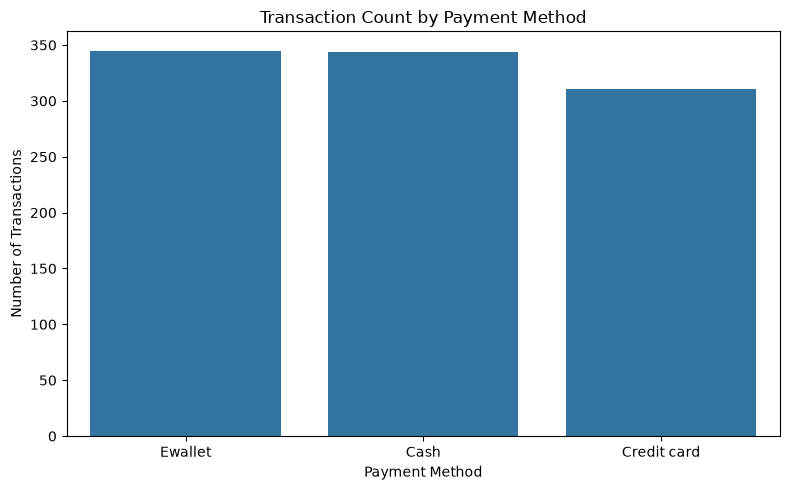

In [21]:
plt.figure(figsize=(8, 5))

sns.countplot(
    data=df_clean,
    x="Payment"
)

plt.title("Transaction Count by Payment Method")
plt.xlabel("Payment Method")
plt.ylabel("Number of Transactions")
plt.tight_layout()
plt.show()

In [22]:
# Analyze sales by day of the week
day_order = [
    "Monday", "Tuesday", "Wednesday", "Thursday",
    "Friday", "Saturday", "Sunday"
]

daily_sales = (
    df_clean.groupby("Day_Name")
    .agg(
        Total_Revenue=("Total", "sum"),
        Transactions=("Invoice ID", "nunique"),
        Average_Transaction_Value=("Total", "mean")
    )
    .reindex(day_order)
)

daily_sales.round(2)

,Total_Revenue,Transactions,Average_Transaction_Value
Day_Name,,,
Monday,37899.08,125,303.19
Tuesday,51482.25,158,325.84
Wednesday,43731.14,143,305.81
Thursday,45349.25,138,328.62
Friday,43926.34,139,316.02
Saturday,56120.81,164,342.20
Sunday,44457.89,133,334.27


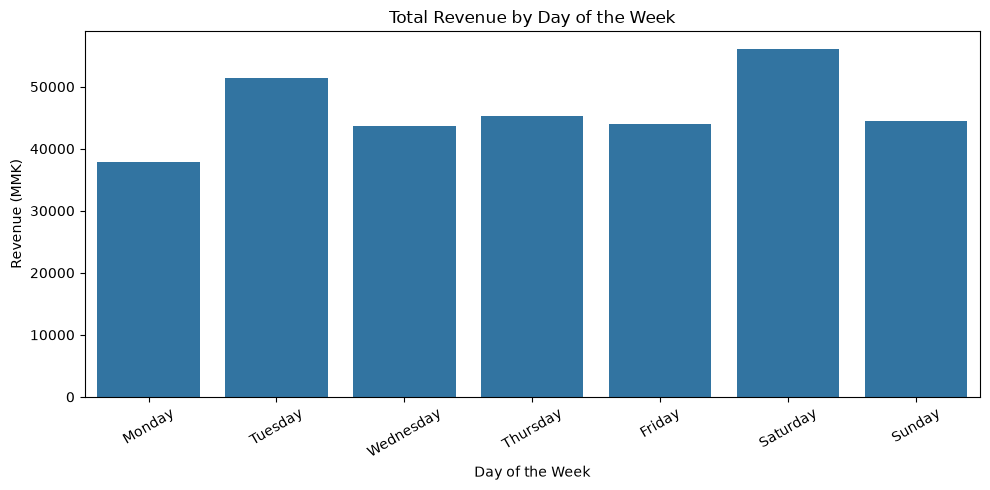

In [23]:
plt.figure(figsize=(10, 5))

sns.barplot(
    data=daily_sales.reset_index(),
    x="Day_Name",
    y="Total_Revenue"
)

plt.title("Total Revenue by Day of the Week")
plt.xlabel("Day of the Week")
plt.ylabel("Revenue (MMK)")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

In [24]:
hourly_sales = (
    df_clean.groupby("Hour")
    .agg(
        Total_Revenue=("Total", "sum"),
        Transactions=("Invoice ID", "nunique"),
        Average_Transaction_Value=("Total", "mean")
    )
)

hourly_sales.round(2)

,Total_Revenue,Transactions,Average_Transaction_Value
Hour,,,
10,31421.48,101,311.10
11,30377.33,90,337.53
12,26065.88,89,292.88
13,34723.23,103,337.12
14,30828.40,83,371.43
15,31179.51,102,305.68
16,25226.32,77,327.61
17,24445.22,74,330.34
18,26030.34,93,279.90


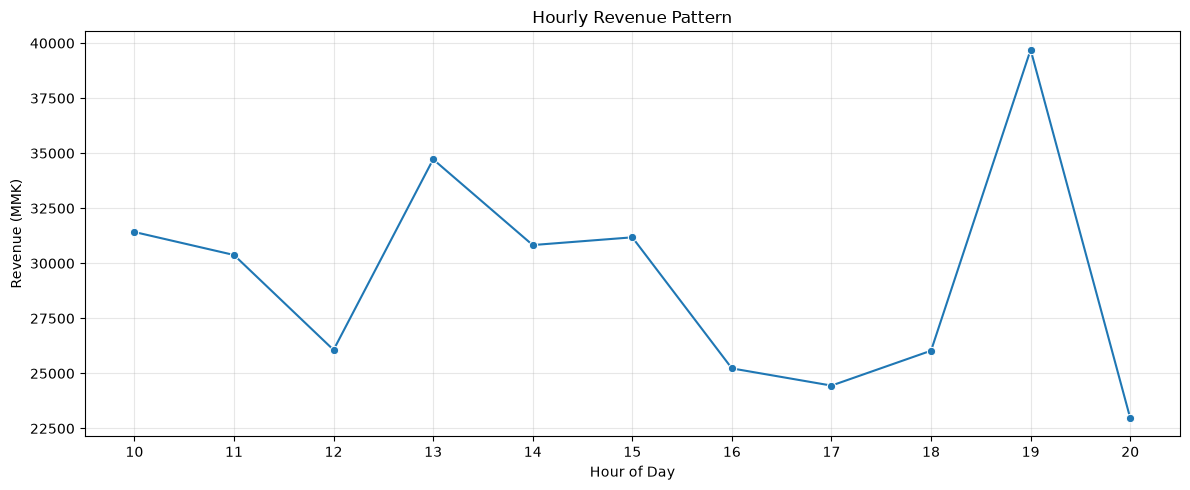

In [25]:
plt.figure(figsize=(12, 5))

sns.lineplot(
    data=hourly_sales.reset_index(),
    x="Hour",
    y="Total_Revenue",
    marker="o"
)

plt.title("Hourly Revenue Pattern")
plt.xlabel("Hour of Day")
plt.ylabel("Revenue (MMK)")
plt.xticks(range(10, 21))
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [26]:
month_order = [1, 2, 3]

monthly_sales = (
    df_clean.groupby("Month")
    .agg(
        Total_Revenue=("Total", "sum"),
        Transactions=("Invoice ID", "nunique"),
        Average_Transaction_Value=("Total", "mean")
    )
    .reindex(month_order)
)

monthly_sales.index = ["January", "February", "March"]

monthly_sales.round(2)

,Total_Revenue,Transactions,Average_Transaction_Value
January,116291.87,352,330.37
February,97219.37,303,320.86
March,109455.51,345,317.26


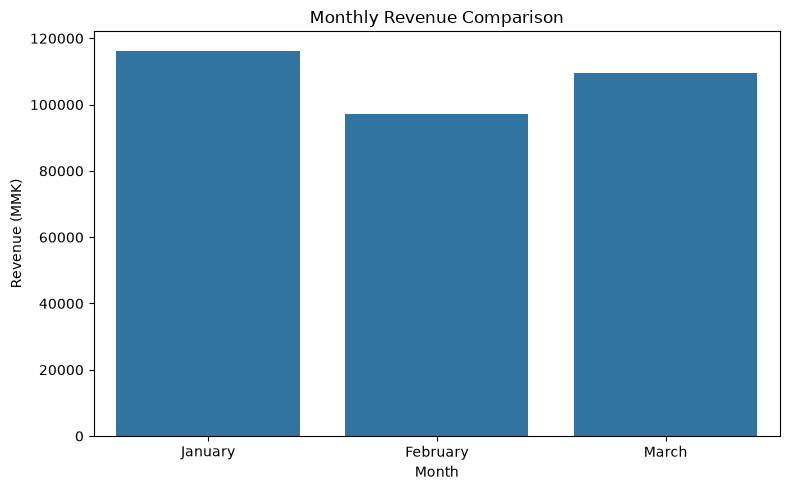

In [27]:
plt.figure(figsize=(8, 5))

sns.barplot(
    data=monthly_sales.reset_index(names="Month"),
    x="Month",
    y="Total_Revenue"
)

plt.title("Monthly Revenue Comparison")
plt.xlabel("Month")
plt.ylabel("Revenue (MMK)")
plt.tight_layout()
plt.show()

In [28]:
rating_analysis = (
    df_clean.groupby("Product line")
    .agg(
        Average_Rating=("Rating", "mean"),
        Median_Rating=("Rating", "median"),
        Number_of_Ratings=("Rating", "count")
    )
    .sort_values("Average_Rating", ascending=False)
)

rating_analysis.round(2)

,Average_Rating,Median_Rating,Number_of_Ratings
Product line,,,
Food and beverages,7.11,7.30,174
Fashion accessories,7.03,6.95,178
Health and beauty,7.00,7.20,152
Electronic accessories,6.92,6.70,170
Sports and travel,6.92,6.70,166
Home and lifestyle,6.84,7.00,160


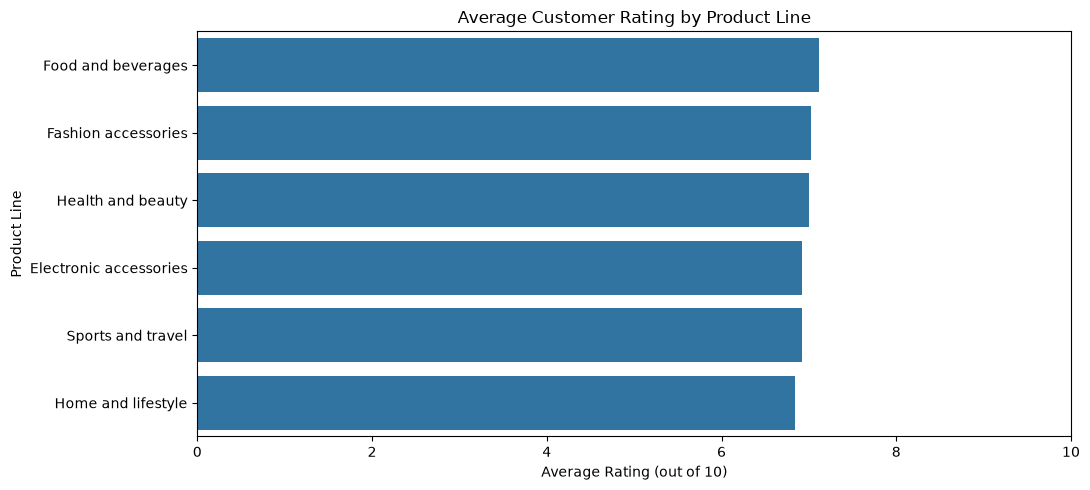

In [29]:
plt.figure(figsize=(11, 5))

sns.barplot(
    data=rating_analysis.reset_index(),
    x="Average_Rating",
    y="Product line"
)

plt.title("Average Customer Rating by Product Line")
plt.xlabel("Average Rating (out of 10)")
plt.ylabel("Product Line")
plt.xlim(0, 10)
plt.tight_layout()
plt.show()

In [30]:
numerical_columns = [
    "Unit price",
    "Quantity",
    "Tax 5%",
    "Total",
    "cogs",
    "gross income",
    "Rating"
]

correlation_matrix = df_clean[numerical_columns].corr()

correlation_matrix.round(2)

,Unit price,Quantity,Tax 5%,Total,cogs,gross income,Rating
Unit price,1.00,0.01,0.63,0.63,0.63,0.63,-0.01
Quantity,0.01,1.00,0.71,0.71,0.71,0.71,-0.02
Tax 5%,0.63,0.71,1.00,1.00,1.00,1.00,-0.04
Total,0.63,0.71,1.00,1.00,1.00,1.00,-0.04
cogs,0.63,0.71,1.00,1.00,1.00,1.00,-0.04
gross income,0.63,0.71,1.00,1.00,1.00,1.00,-0.04
Rating,-0.01,-0.02,-0.04,-0.04,-0.04,-0.04,1.00


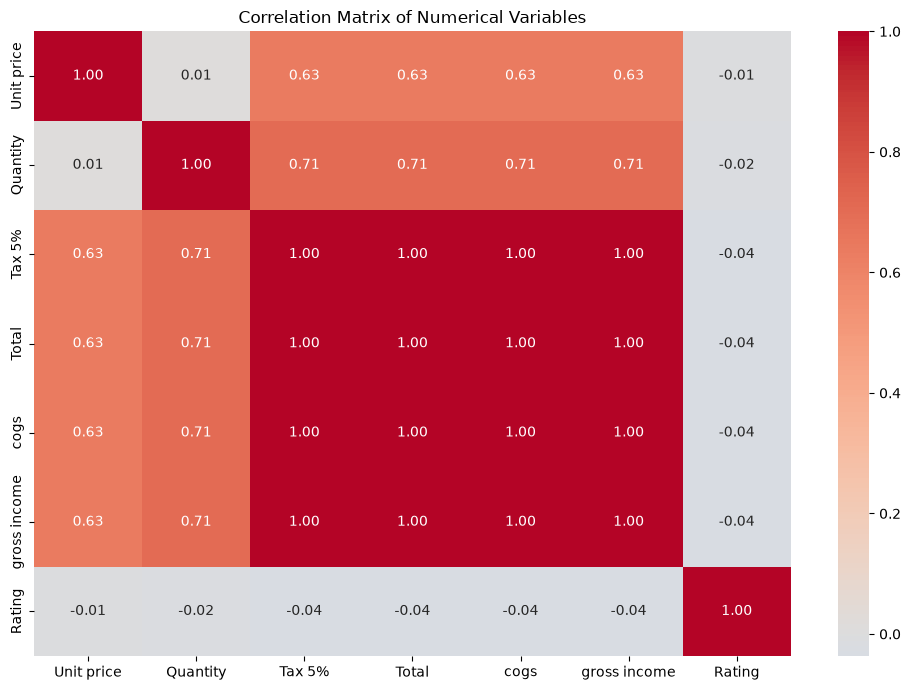

In [31]:
plt.figure(figsize=(10, 7))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    center=0
)

plt.title("Correlation Matrix of Numerical Variables")
plt.tight_layout()
plt.show()

In [32]:
import sqlite3

# Create a SQLite database
conn = sqlite3.connect("supermarket_sales.db")

# Load the cleaned dataset into a SQL table
df_clean.to_sql(
    "sales",
    conn,
    if_exists="replace",
    index=False
)

print("Dataset successfully loaded into SQLite!")

Dataset successfully loaded into SQLite!


In [33]:
# Check the number of records
pd.read_sql_query(
    "SELECT COUNT(*) AS total_records FROM sales",
    conn
)

,total_records
0,1000


In [34]:
pd.read_sql_query(
    "SELECT * FROM sales LIMIT 5",
    conn
)

,Invoice ID,Branch,City,Customer type,Gender,Product line,Unit price,Quantity,Tax 5%,Total,...,Payment,cogs,gross margin percentage,gross income,Rating,Month,Month_Name,Day,Day_Name,Hour
0,750-67-8428,A,Yangon,Member,Female,Health and beauty,74.69,7,26.1415,548.9715,...,Ewallet,522.83,4.761905,26.1415,9.1,1,January,5,Saturday,13
1,226-31-3081,C,Naypyitaw,Normal,Female,Electronic accessories,15.28,5,3.8200,80.2200,...,Cash,76.40,4.761905,3.8200,9.6,3,March,8,Friday,10
2,631-41-3108,A,Yangon,Normal,Male,Home and lifestyle,46.33,7,16.2155,340.5255,...,Credit card,324.31,4.761905,16.2155,7.4,3,March,3,Sunday,13
3,123-19-1176,A,Yangon,Member,Male,Health and beauty,58.22,8,23.2880,489.0480,...,Ewallet,465.76,4.761905,23.2880,8.4,1,January,27,Sunday,20
4,373-73-7910,A,Yangon,Normal,Male,Sports and travel,86.31,7,30.2085,634.3785,...,Ewallet,604.17,4.761905,30.2085,5.3,2,February,8,Friday,10


In [35]:
query = """
SELECT
    "Product line" AS product_line,
    COUNT(DISTINCT "Invoice ID") AS transactions,
    SUM(Quantity) AS units_sold,
    ROUND(SUM(Total), 2) AS total_revenue,
    ROUND(SUM("gross income"), 2) AS total_gross_income,
    ROUND(AVG(Rating), 2) AS average_rating
FROM sales
GROUP BY "Product line"
ORDER BY total_revenue DESC;
"""

product_sql = pd.read_sql_query(query, conn)
product_sql

,product_line,transactions,units_sold,total_revenue,total_gross_income,average_rating
0,Food and beverages,174,952,56144.84,2673.56,7.11
1,Sports and travel,166,920,55122.83,2624.90,6.92
2,Electronic accessories,170,971,54337.53,2587.50,6.92
3,Fashion accessories,178,902,54305.90,2586.00,7.03
4,Home and lifestyle,160,911,53861.91,2564.85,6.84
5,Health and beauty,152,854,49193.74,2342.56,7.00


In [36]:
query = """
SELECT
    Branch,
    City,
    COUNT(DISTINCT "Invoice ID") AS transactions,
    ROUND(SUM(Total), 2) AS total_revenue,
    ROUND(AVG(Total), 2) AS average_transaction_value,
    ROUND(SUM("gross income"), 2) AS total_gross_income
FROM sales
GROUP BY Branch, City
ORDER BY total_revenue DESC;
"""

branch_sql = pd.read_sql_query(query, conn)
branch_sql

,Branch,City,transactions,total_revenue,average_transaction_value,total_gross_income
0,C,Naypyitaw,328,110568.71,337.10,5265.18
1,A,Yangon,340,106200.37,312.35,5057.16
2,B,Mandalay,332,106197.67,319.87,5057.03


In [37]:
query = """
SELECT
    "Customer type" AS customer_type,
    COUNT(DISTINCT "Invoice ID") AS transactions,
    ROUND(SUM(Total), 2) AS total_revenue,
    ROUND(AVG(Total), 2) AS average_transaction_value,
    ROUND(AVG(Rating), 2) AS average_rating
FROM sales
GROUP BY "Customer type"
ORDER BY total_revenue DESC;
"""

customer_sql = pd.read_sql_query(query, conn)
customer_sql

,customer_type,transactions,total_revenue,average_transaction_value,average_rating
0,Member,501,164223.44,327.79,6.94
1,Normal,499,158743.31,318.12,7.01


In [38]:
query = """
SELECT
    strftime('%Y-%m', Date) AS sales_month,
    COUNT(DISTINCT "Invoice ID") AS transactions,
    ROUND(SUM(Total), 2) AS total_revenue,
    ROUND(AVG(Total), 2) AS average_transaction_value
FROM sales
GROUP BY strftime('%Y-%m', Date)
ORDER BY sales_month;
"""

monthly_sql = pd.read_sql_query(query, conn)
monthly_sql

,sales_month,transactions,total_revenue,average_transaction_value
0,2019-01,352,116291.87,330.37
1,2019-02,303,97219.37,320.86
2,2019-03,345,109455.51,317.26


In [39]:
query = """
SELECT
    "Invoice ID" AS invoice_id,
    Branch,
    City,
    "Product line" AS product_line,
    Quantity,
    ROUND(Total, 2) AS total_amount,
    Payment
FROM sales
ORDER BY Total DESC
LIMIT 10;
"""

top_transactions = pd.read_sql_query(query, conn)
top_transactions

,invoice_id,Branch,City,product_line,Quantity,total_amount,Payment
0,860-79-0874,C,Naypyitaw,Fashion accessories,10,1042.65,Credit card
1,687-47-8271,A,Yangon,Fashion accessories,10,1039.29,Credit card
2,283-26-5248,C,Naypyitaw,Food and beverages,10,1034.46,Ewallet
3,751-41-9720,C,Naypyitaw,Home and lifestyle,10,1023.75,Ewallet
4,303-96-2227,B,Mandalay,Home and lifestyle,10,1022.49,Ewallet
5,744-16-7898,B,Mandalay,Home and lifestyle,10,1022.39,Credit card
6,271-88-8734,C,Naypyitaw,Fashion accessories,10,1020.71,Credit card
7,234-65-2137,C,Naypyitaw,Home and lifestyle,10,1003.59,Cash
8,554-42-2417,C,Naypyitaw,Sports and travel,10,1002.12,Cash
9,325-77-6186,A,Yangon,Home and lifestyle,10,951.83,Ewallet


In [40]:
# Compare total revenue calculated by Pandas and SQL
pandas_revenue = df_clean["Total"].sum()

sql_revenue = pd.read_sql_query(
    "SELECT SUM(Total) AS revenue FROM sales",
    conn
)["revenue"].iloc[0]

print(f"Pandas revenue: {pandas_revenue:.2f}")
print(f"SQL revenue:    {sql_revenue:.2f}")
print(f"Match: {np.isclose(pandas_revenue, sql_revenue)}")

Pandas revenue: 322966.75
SQL revenue:    322966.75
Match: True


In [41]:
conn.close()

In [42]:
# Stage 6: Final Business Summary

# Overall KPIs
kpis = {
    "Total Revenue (MMK)": df_clean["Total"].sum(),
    "Total Transactions": df_clean["Invoice ID"].nunique(),
    "Total Units Sold": df_clean["Quantity"].sum(),
    "Average Transaction Value (MMK)": df_clean["Total"].mean(),
    "Total Gross Income (MMK)": df_clean["gross income"].sum(),
    "Average Customer Rating": df_clean["Rating"].mean()
}

kpi_report = pd.DataFrame(
    list(kpis.items()),
    columns=["Metric", "Value"]
)

display(kpi_report.round(2))

,Metric,Value
0,Total Revenue (MMK),322966.75
1,Total Transactions,1000.00
2,Total Units Sold,5510.00
3,Average Transaction Value (MMK),322.97
4,Total Gross Income (MMK),15379.37
5,Average Customer Rating,6.97


In [43]:
# Product-line performance
product_summary = (
    df_clean.groupby("Product line")
    .agg(
        Revenue=("Total", "sum"),
        Gross_Income=("gross income", "sum"),
        Units_Sold=("Quantity", "sum"),
        Average_Rating=("Rating", "mean")
    )
    .sort_values("Revenue", ascending=False)
)

# Branch performance
branch_summary = (
    df_clean.groupby(["Branch", "City"])
    .agg(
        Revenue=("Total", "sum"),
        Transactions=("Invoice ID", "nunique"),
        Average_Transaction_Value=("Total", "mean"),
        Average_Rating=("Rating", "mean")
    )
    .sort_values("Revenue", ascending=False)
)

# Customer segment performance
customer_summary = (
    df_clean.groupby("Customer type")
    .agg(
        Revenue=("Total", "sum"),
        Transactions=("Invoice ID", "nunique"),
        Average_Transaction_Value=("Total", "mean"),
        Average_Rating=("Rating", "mean")
    )
)

# Payment performance
payment_summary = (
    df_clean.groupby("Payment")
    .agg(
        Transactions=("Invoice ID", "nunique"),
        Revenue=("Total", "sum")
    )
    .sort_values("Transactions", ascending=False)
)

print("PRODUCT LINE PERFORMANCE")
display(product_summary.round(2))

print("BRANCH PERFORMANCE")
display(branch_summary.round(2))

print("CUSTOMER SEGMENTS")
display(customer_summary.round(2))

print("PAYMENT METHODS")
display(payment_summary.round(2))

PRODUCT LINE PERFORMANCE


,Revenue,Gross_Income,Units_Sold,Average_Rating
Product line,,,,
Food and beverages,56144.84,2673.56,952,7.11
Sports and travel,55122.83,2624.90,920,6.92
Electronic accessories,54337.53,2587.50,971,6.92
Fashion accessories,54305.90,2586.00,902,7.03
Home and lifestyle,53861.91,2564.85,911,6.84
Health and beauty,49193.74,2342.56,854,7.00


BRANCH PERFORMANCE


,,Revenue,Transactions,Average_Transaction_Value,Average_Rating
Branch,City,,,,
C,Naypyitaw,110568.71,328,337.10,7.07
A,Yangon,106200.37,340,312.35,7.03
B,Mandalay,106197.67,332,319.87,6.82


CUSTOMER SEGMENTS


,Revenue,Transactions,Average_Transaction_Value,Average_Rating
Customer type,,,,
Member,164223.44,501,327.79,6.94
Normal,158743.30,499,318.12,7.01


PAYMENT METHODS


,Transactions,Revenue
Payment,,
Ewallet,345,109993.11
Cash,344,112206.57
Credit card,311,100767.07


In [44]:
from pathlib import Path

# Create output directory
output_dir = Path("../outputs")
output_dir.mkdir(parents=True, exist_ok=True)

# Export analysis tables
kpi_report.to_csv(output_dir / "kpi_report.csv", index=False)
product_summary.to_csv(output_dir / "product_analysis.csv")
branch_summary.to_csv(output_dir / "branch_analysis.csv")
customer_summary.to_csv(output_dir / "customer_analysis.csv")
payment_summary.to_csv(output_dir / "payment_analysis.csv")
monthly_sales.to_csv(output_dir / "monthly_sales.csv")

print("Analysis tables exported successfully!")

Analysis tables exported successfully!


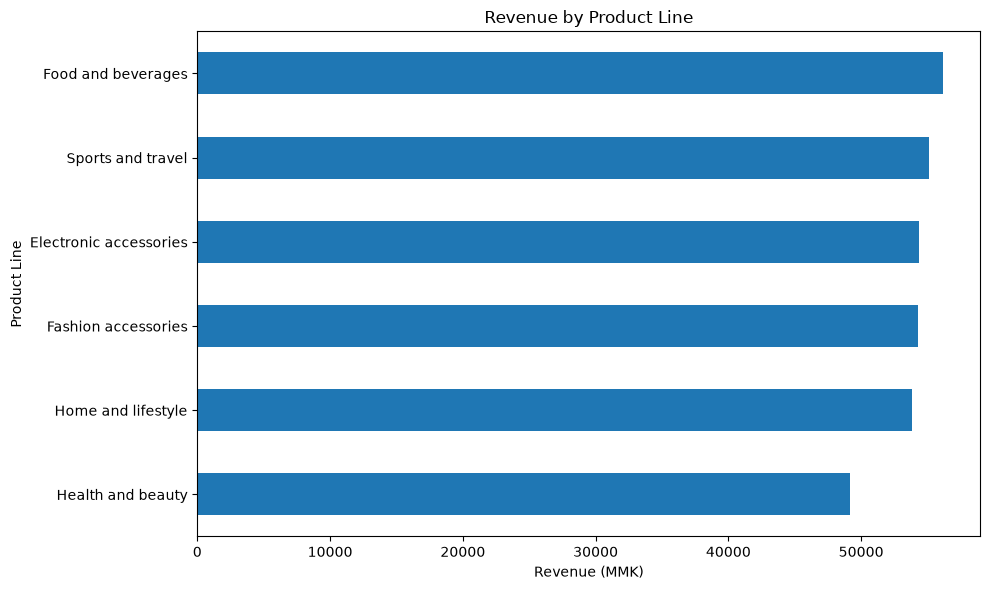

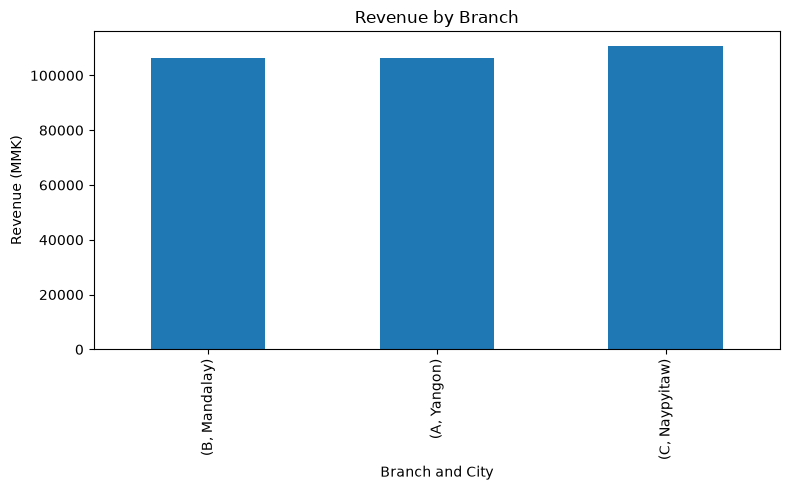

NameError: name 'hourly_summary' is not defined

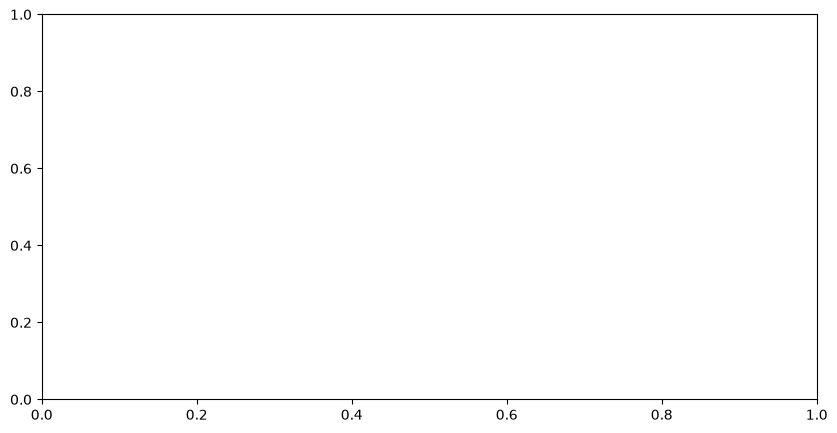

In [45]:
# 1. Revenue by product line
fig, ax = plt.subplots(figsize=(10, 6))

product_summary["Revenue"].sort_values().plot(
    kind="barh", ax=ax
)

ax.set_title("Revenue by Product Line")
ax.set_xlabel("Revenue (MMK)")
ax.set_ylabel("Product Line")
fig.tight_layout()
fig.savefig(output_dir / "revenue_by_product.png", dpi=150)
plt.show()


# 2. Revenue by branch
fig, ax = plt.subplots(figsize=(8, 5))

branch_summary["Revenue"].sort_values().plot(
    kind="bar", ax=ax
)

ax.set_title("Revenue by Branch")
ax.set_xlabel("Branch and City")
ax.set_ylabel("Revenue (MMK)")
fig.tight_layout()
fig.savefig(output_dir / "revenue_by_branch.png", dpi=150)
plt.show()


# 3. Revenue by hour
fig, ax = plt.subplots(figsize=(10, 5))

hourly_summary["Revenue"].plot(
    kind="line", marker="o", ax=ax
)

ax.set_title("Hourly Revenue Pattern")
ax.set_xlabel("Hour of Day")
ax.set_ylabel("Revenue (MMK)")
fig.tight_layout()
fig.savefig(output_dir / "hourly_revenue.png", dpi=150)
plt.show()

print("Portfolio charts saved successfully!")